In [1]:
import pandas as pd
from sklearn.datasets import load_wine

wine_data = load_wine(as_frame=True)

df = wine_data.frame
print("--- Primele 5 rânduri din dataset ---")
print(df.head().to_string())

print("\n--- Caracteristicile disponibile ---")
print(wine_data.feature_names)

--- Primele 5 rânduri din dataset ---
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline  target
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0       0
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0       0
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0       0
3    14.37        1.95  2.50               16.8      113.0           3.85        3.49                  0.24             2.18             7.80  0.86                          3.45   14

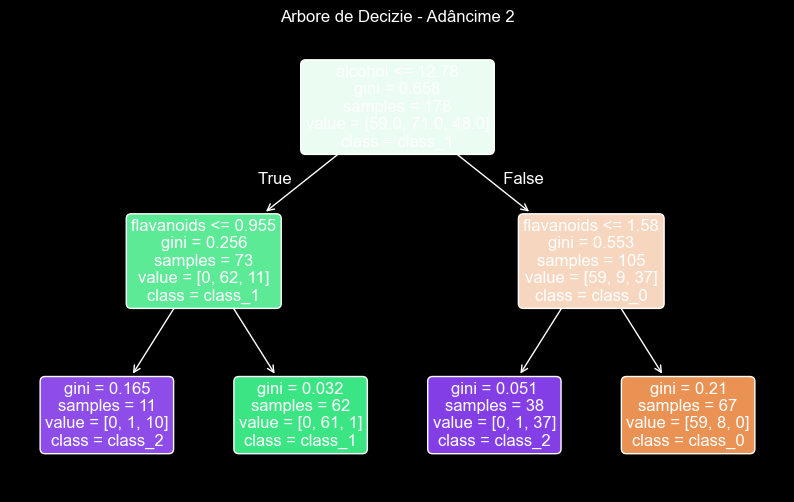

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

X_ex2 = df[['alcohol', 'flavanoids']]
y = wine_data.target

tree_ex2 = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_ex2.fit(X_ex2, y)

plt.figure(figsize=(10, 6))
plot_tree(tree_ex2,
          feature_names=['alcohol', 'flavanoids'],
          class_names=wine_data.target_names,
          filled=True,
          rounded=True)
plt.title("Arbore de Decizie - Adâncime 2")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = wine_data.data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

tree_full = DecisionTreeClassifier(max_depth=None, random_state=42)
tree_full.fit(X_train, y_train)

y_pred = tree_full.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- Acuratețea modelului (max_depth=None) ---")
print(f"Acuratețe: {accuracy * 100:.2f}%")


--- Acuratețea modelului (max_depth=None) ---
Acuratețe: 96.30%


In [4]:
import numpy as np

importances = tree_full.feature_importances_

feat_imp_df = pd.DataFrame({
    'Caracteristică': wine_data.feature_names,
    'Importanță': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importanță', ascending=False)

print("\n--- Importanța caracteristicilor ---")
print(feat_imp_df.to_string(index=False))


--- Importanța caracteristicilor ---
              Caracteristică  Importanță
                  flavanoids    0.414659
             color_intensity    0.411475
                     proline    0.128900
                         ash    0.023961
                     alcohol    0.021005
                   magnesium    0.000000
           alcalinity_of_ash    0.000000
                  malic_acid    0.000000
               total_phenols    0.000000
             proanthocyanins    0.000000
        nonflavanoid_phenols    0.000000
                         hue    0.000000
od280/od315_of_diluted_wines    0.000000
